# LightGBM v2 con todos los canales fisiológicos

Usa el **LightGBM DART ganador de Jhoan v2**, con los mismos hiperparámetros y
preprocesamiento de `sleep-staging`, añadiendo EOG y EMG a los dos EEG.
`Marker` queda excluido. Ejecuta las celdas en orden con el entorno del proyecto.

Esta primera prueba mantiene el filtro común de 0,3–35 Hz y las mismas features
por canal para medir el efecto de añadir señales. No incorpora todavía filtros
ni features especializados para EOG/EMG. El hipnograma solo aporta las etiquetas;
el preprocesamiento sigue siendo el compartido con inferencia.

## 1. Configuración
`MAX_SUBJECTS = None` usa los 22 sujetos y sus 44 noches. Puedes usar `3` para una
prueba rápida del flujo, cuyo resultado no es comparable con el baseline completo.
MLflow permanece desactivado. El modelo mixto se guarda por separado como artefacto experimental.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'data.dvc').is_file()
)
PACKAGE_SRC = REPO_ROOT / 'packages' / 'sleep-staging' / 'src'
if str(PACKAGE_SRC) not in sys.path:
    sys.path.insert(0, str(PACKAGE_SRC))

from sleep_staging import PreprocessingConfig, PreprocessingPipeline
from sleep_staging.datasets import discover_sleep_telemetry_records
from sleep_staging.training import (
    MlflowConfig, create_lightgbm_classifier, display_evaluation,
    load_or_build_supervised_dataset, split_by_subject, train_and_evaluate,
)

SEED = 42
MAX_SUBJECTS = None
PREPROCESSING = PreprocessingConfig(
    channels=('EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'EMG submental'),
    rolling_windows=(3, 5, 11),
    include_subepoch_features=True,
    subepoch_seconds=5.0,
    include_signal_quality_features=True,
    temporal_difference_offsets=(1, 2),
)
PIPELINE = PreprocessingPipeline(PREPROCESSING)
print('Canales:', PREPROCESSING.channels)

Canales: ('EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal', 'EMG submental')


## 2. Dataset
La primera ejecución calcula las features y guarda un caché propio según la
configuración de cuatro canales. Las siguientes ejecuciones reutilizan ese caché.
Se conservan juntas todas las noches de cada sujeto.

In [2]:
records = discover_sleep_telemetry_records(REPO_ROOT / 'data' / 'sleep-telemetry')
if MAX_SUBJECTS is not None:
    if not isinstance(MAX_SUBJECTS, int) or MAX_SUBJECTS < 2:
        raise ValueError('MAX_SUBJECTS debe ser None o un entero >= 2')
    selected = sorted({record.subject_id for record in records})[:MAX_SUBJECTS]
    records = [record for record in records if record.subject_id in selected]

dataset = load_or_build_supervised_dataset(
    records, PIPELINE, REPO_ROOT / 'data' / 'processed' / 'supervised',
)
print(f'Dataset: {dataset.features.shape[0]} épocas × {dataset.features.shape[1]} features')
print(f'Sujetos: {dataset.metadata.subject_id.nunique()} | Registros: {len(records)}')
display(dataset.labels.value_counts().rename('épocas').to_frame())

Cargando dataset desde caché: E:\PROJECTS\Maestria Inteligencia Artificial\masterIADesarollo\micro-proyecto-grupo-7\data\processed\supervised\18c3c51b05e3


Dataset: 42691 épocas × 2280 features
Sujetos: 22 | Registros: 44


,épocas
stage,
N2,19851
REM,8349
N3,6415
W,4423
N1,3653


## 3. Separación por sujeto
Mismo holdout del notebook v2: 20 % de sujetos, semilla 42. Con el dataset completo
se esperan `S01`, `S02`, `S10`, `S15` y `S17` en validación.

In [3]:
split = split_by_subject(dataset, validation_size=0.20, random_state=SEED)
assert set(split.train_subjects).isdisjoint(split.validation_subjects)
print(f'Train: {split.X_train.shape} | {len(split.train_subjects)} sujetos')
print(f'Validación: {split.X_validation.shape} | {len(split.validation_subjects)} sujetos')
print('Sujetos de validación:', split.validation_subjects)

Train: (32762, 2280) | 17 sujetos
Validación: (9929, 2280) | 5 sujetos
Sujetos de validación: ('S01', 'S02', 'S10', 'S15', 'S17')


## 4. Entrenar el LightGBM ganador
Se conservan los parámetros del ganador v2: DART, 667 árboles, 36 hojas,
learning rate 0,03 y los mismos pesos por clase. No se realiza grid search.

In [4]:
LGBM_PARAMS = {
    'boosting_type': 'dart',
    'learning_rate': 0.03,
    'min_child_samples': 25,
    'n_estimators': 667,
    'num_leaves': 36,
    'max_depth': 8,
    'drop_rate': 0.10,
    'skip_drop': 0.50,
    'reg_alpha': 0.10,
    'reg_lambda': 1.50,
    'class_weight': {'N1': 2.20, 'N2': 0.41, 'N3': 1.56, 'REM': 1.00, 'W': 2.01},
}
model = create_lightgbm_classifier(random_state=SEED, **LGBM_PARAMS)
evaluation = train_and_evaluate(
    model, split,
    model_name='LightGBM v2 EEG + EOG + EMG',
    parameters=LGBM_PARAMS,
    mlflow_config=MlflowConfig(enabled=False),
)

## 5. Resultados
Métricas globales, por estadio y matriz de confusión. La tabla compara con la
salida histórica del v2 de dos EEG; kappa histórico está redondeado a cuatro decimales.

**Lectura del experimento:** el holdout ya se consultó durante los ajustes del
modelo anterior. Esta comparación es exploratoria; una mejora debe confirmarse
con `GroupKFold` por sujeto antes de declarar un nuevo ganador.


LightGBM v2 EEG + EOG + EMG
accuracy    0.8170
kappa       0.7518
f1_macro    0.7938

Métricas por estadio:
     precision  recall  f1-score  support
W       0.8932  0.8424    0.8670   1161.0
N1      0.5389  0.6021    0.5688    862.0
N2      0.7818  0.8697    0.8234   3868.0
N3      0.9634  0.7032    0.8130   2207.0
REM     0.8682  0.9279    0.8970   1831.0


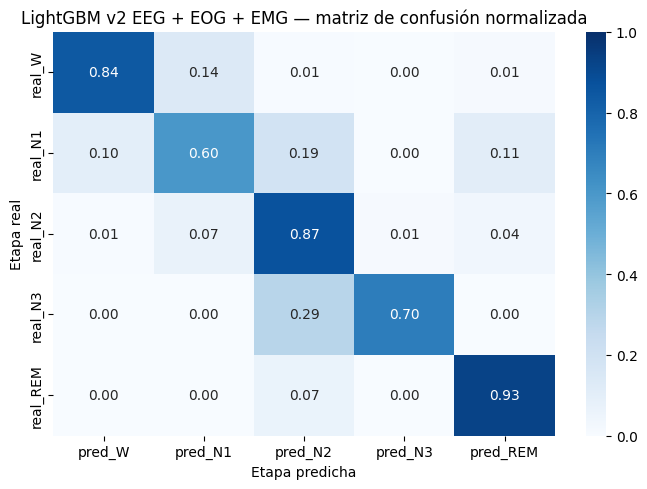

,accuracy,kappa,f1_macro,f1_N1
v2: dos EEG (histórico),0.8019,0.7312,0.7696,0.5117
v2: EEG + EOG + EMG,0.8170,0.7518,0.7938,0.5688
Cambio frente al histórico,0.0151,0.0206,0.0243,0.0571


In [5]:
display_evaluation(evaluation)

if MAX_SUBJECTS is None:
    baseline = pd.Series({
        'accuracy': 0.8018934434484842,
        'kappa': 0.7312,
        'f1_macro': 0.769561855470513,
        'f1_N1': 0.5116784356328082,
    }, name='v2: dos EEG (histórico)')
    current = pd.Series({
        **evaluation.metrics,
        'f1_N1': float(evaluation.per_class.loc['N1', 'f1-score']),
    }, name='v2: EEG + EOG + EMG')
    comparison = pd.concat([baseline, current], axis=1).T
    comparison.loc['Cambio frente al histórico'] = current - baseline
    display(comparison.round(4))
else:
    print('Prueba con pocos sujetos: no comparar con las métricas del dataset completo.')

## 6. Telemetry + Cassette con los mismos hiperparámetros

Ejecuta el cuaderno completo con `MAX_SUBJECTS = None` después de `dvc pull`. Se conservan los cinco sujetos de validación de Telemetry y se reserva el 20 % de los sujetos disponibles de Cassette con la misma semilla. Ambos modelos se evalúan en exactamente las mismas épocas de cada cohorte.

En los EDF de Cassette, los dos EEG y el EOG están a 100 Hz y el EMG a 1 Hz. Extraemos las mismas características de los tres canales rápidos. Las columnas del EMG de alta frecuencia quedan ausentes en Cassette y LightGBM trata esos valores como faltantes. Las cuatro señales de Telemetry conservan su definición original. Las épocas con etiquetas válidas incluyen la vigilia completa.

In [6]:
from dataclasses import replace
from pathlib import Path
from tempfile import gettempdir

import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score, cohen_kappa_score, f1_score
from sleep_staging.datasets import VALID_STAGES, discover_sleep_cassette_records
from sleep_staging.training import SupervisedDataset

if MAX_SUBJECTS is not None:
    raise ValueError('La comparación entre cohortes requiere el control completo de Telemetry.')

cassette_dir = REPO_ROOT / 'data' / 'sleep-cassette'
sc_records = discover_sleep_cassette_records(cassette_dir)
paired_files = {p.name for r in sc_records for p in (r.psg_path, r.hypnogram_path)}
unpaired = sorted(p.name for p in cassette_dir.glob('*.edf') if p.name not in paired_files)
print(f'Cassette: {len(sc_records)} pares completos. EDF sin pareja: {len(unpaired)}.')

common_channels = tuple(ch for ch in PREPROCESSING.channels if ch != 'EMG submental')
sc_pipeline = PreprocessingPipeline(replace(PREPROCESSING, channels=common_channels))
sc_cache = Path(gettempdir()) / 'sleep-edfx-sc-features-v1'
sc_nights = [
    load_or_build_supervised_dataset([r], sc_pipeline, sc_cache, verbose=False)
    for r in sc_records
]
sc = SupervisedDataset(
    features=pd.concat([night.features for night in sc_nights], ignore_index=True),
    labels=pd.concat([night.labels for night in sc_nights], ignore_index=True),
    metadata=pd.concat([night.metadata for night in sc_nights], ignore_index=True),
)
del sc_nights
expected_shared = {col for col in dataset.features if not col.startswith('EMG submental_')}
assert set(sc.features) == expected_shared
sc_split = split_by_subject(sc, validation_size=0.2, random_state=SEED)
del sc
assert set(sc_split.train_subjects).isdisjoint(sc_split.validation_subjects)
assert set(dataset.metadata.subject_id).isdisjoint(sc_split.metadata_train.subject_id)
print('Sujetos Cassette de entrenamiento:', sc_split.train_subjects)
print('Sujetos Cassette de validación:', sc_split.validation_subjects)
print('Épocas de Cassette, entrenamiento y validación:', len(sc_split.y_train), len(sc_split.y_validation))

Cassette: 12 pares completos. EDF sin pareja: 51.


Sujetos Cassette de entrenamiento: ('SC407', 'SC410', 'SC417', 'SC426', 'SC434', 'SC435', 'SC441', 'SC452', 'SC482')
Sujetos Cassette de validación: ('SC406', 'SC457', 'SC472')
Épocas de Cassette, entrenamiento y validación: 24472 8449


In [7]:
# Reindexar conserva el orden del experimento de cuatro canales e introduce NaN solo en el EMG.
sc_train = sc_split.X_train.reindex(columns=split.X_train.columns)
sc_val = sc_split.X_validation.reindex(columns=split.X_train.columns)
X_combined = pd.concat([split.X_train, sc_train], ignore_index=True)
y_combined = pd.concat([split.y_train, sc_split.y_train], ignore_index=True)
mixed_model = create_lightgbm_classifier(random_state=SEED, **LGBM_PARAMS)
mixed_model.fit(X_combined, y_combined)
print(f'Entrenamiento mixto: {len(y_combined)} épocas, {len(X_combined.columns)} características.')
del X_combined, y_combined, sc_train

Entrenamiento mixto: 57234 épocas, 2280 características.


In [8]:
def scores(y_true, y_pred):
    return {
        'épocas': len(y_true),
        'accuracy': accuracy_score(y_true, y_pred),
        'kappa': cohen_kappa_score(y_true, y_pred),
        'f1_macro': f1_score(y_true, y_pred, labels=VALID_STAGES, average='macro', zero_division=0),
        'f1_N1': f1_score(y_true, y_pred, labels=['N1'], average=None, zero_division=0)[0],
    }

predictions = {}
rows = []
for training, classifier in [('Telemetry', model), ('Telemetry + Cassette', mixed_model)]:
    for cohort, X, y in [('Telemetry', split.X_validation, split.y_validation),
                         ('Cassette', sc_val, sc_split.y_validation)]:
        pred = classifier.predict(X)
        predictions[training, cohort] = pred
        rows.append({'entrenamiento': training, 'validación': cohort, **scores(y, pred)})
display(pd.DataFrame(rows).set_index(['entrenamiento', 'validación']).round(4))

épocas  accuracy   kappa  f1_macro   f1_N1
entrenamiento        validación                                            
Telemetry            Telemetry     9929    0.8170  0.7518    0.7938  0.5688
                     Cassette      8449    0.3109  0.1436    0.3438  0.0244
Telemetry + Cassette Telemetry     9929    0.8174  0.7532    0.7940  0.5722
                     Cassette      8449    0.8882  0.7603    0.7672  0.4609

## 7. Comparación en las mismas épocas que la CRNN de Telemetry

El archivo de predicciones LOSO del compañero contiene etiquetas y predicciones concatenadas por fold. Reconstruimos el recorte de vigilia de 30 minutos y el orden de los 22 folds de su notebook, y exigimos coincidencia de toda la secuencia de etiquetas antes de cruzar los resultados por noche y época. Se puntúan los cinco sujetos reservados del LightGBM. La CRNN usó un modelo distinto por sujeto y tuvo acceso a más sujetos de entrenamiento en cada fold. Este cruce evalúa la CRNN pura. La etapa LightGBM sobre los embeddings del compañero requiere su propia evaluación.

In [9]:
reference = REPO_ROOT / 'data' / 'referencias' / 'resultados_loso_22pacientes_v5.npz'
labeled = dataset.metadata.assign(stage=dataset.labels)
trimmed = []
margin = int(30 * 60 / PREPROCESSING.epoch_seconds)
for _, night in labeled.groupby('record_id', sort=False):
    asleep = night.loc[night.stage.ne('W'), 'epoch_index']
    if len(asleep):
        night = night[night.epoch_index.between(asleep.min() - margin, asleep.max() + margin)]
    trimmed.append(night)
trimmed = pd.concat(trimmed, ignore_index=True)
folds = GroupKFold(n_splits=trimmed.subject_id.nunique())
order = np.concatenate([test for _, test in folds.split(trimmed, groups=trimmed.subject_id)])
ordered = trimmed.iloc[order].copy()
with np.load(reference, allow_pickle=False) as saved:
    labels = np.asarray(VALID_STAGES)
    np.testing.assert_array_equal(ordered.stage.to_numpy(), labels[saved['y_true']])
    ordered['crnn'] = labels[saved['y_pred_raw']]

common = split.metadata_validation.assign(
    stage=split.y_validation, lgbm=evaluation.predictions,
    lgbm_mixto=predictions['Telemetry + Cassette', 'Telemetry'],
).merge(ordered[['record_id', 'epoch_index', 'stage', 'crnn']],
        on=['record_id', 'epoch_index', 'stage'], validate='one_to_one')
assert len(common) == ordered.subject_id.isin(split.validation_subjects).sum()
display(pd.DataFrame({k: scores(common.stage, common[k]) for k in ['lgbm', 'lgbm_mixto', 'crnn']}).T.round(4))

,épocas,accuracy,kappa,f1_macro,f1_N1
lgbm,9883.0,0.8161,0.7502,0.7927,0.5688
lgbm_mixto,9883.0,0.8166,0.7516,0.7928,0.5722
crnn,9883.0,0.7593,0.6686,0.7219,0.4457


## 8. Guardar el modelo mixto

El archivo de experimento registra clases, orden de las 2.280 columnas, sujetos, hiperparámetros y los dos perfiles de preprocesamiento. El directorio de salida se sincroniza con DVC.

In [ ]:
import json
from dataclasses import asdict
from lightgbm import Booster

export_dir = REPO_ROOT / 'data' / 'experimentos' / 'lightgbm_st_sc'
export_dir.mkdir(parents=True, exist_ok=True)
weights = export_dir / 'model.txt'
mixed_model.booster_.save_model(str(weights))
schema = {
    'classes': mixed_model.classes_.tolist(),
    'feature_columns': split.X_train.columns.tolist(),
    'preprocessing_telemetry': asdict(PREPROCESSING),
    'preprocessing_cassette': asdict(sc_pipeline.config),
    'missing_cassette_features': 'EMG submental: NaN tras reindexar por feature_columns',
    'parameters': mixed_model.get_params(),
    'train_subjects': list(split.train_subjects + sc_split.train_subjects),
    'validation_subjects': list(split.validation_subjects + sc_split.validation_subjects),
}
(export_dir / 'experimento.json').write_text(json.dumps(schema, ensure_ascii=False, indent=2), encoding='utf-8')
reloaded = Booster(model_file=str(weights))
for sample in (split.X_validation.head(32), sc_val.head(32)):
    np.testing.assert_allclose(reloaded.predict(sample), mixed_model.predict_proba(sample))
print('Modelo mixto guardado y recargado. Probabilidades verificadas en ambas cohortes.')

## 9. Comparación directa con el híbrido V6 del compañero

La fase C de `model_v6.ipynb` concatena tres vectores de 64 variables y aplica LightGBM y Viterbi. De los tres sujetos Cassette reservados para el modelo tabular, SC406 se usó para entrenar el híbrido. Quedan SC457 y SC472 para la comparación. Se respeta el recorte de vigilia de 30 minutos de V6 y se verifica cada etiqueta y su número de época. Los pesos de ambos modelos y la matriz de transición del HMM se recuperan mediante `dvc pull`.

La matriz de transición usa las 85.796 épocas de ajuste originales. Las anotaciones de las primeras 40 noches Cassette se verificaron contra el catálogo Sleep PhysioNet incluido en MNE. [Sleep-EDFx 1.0.0](https://physionet.org/content/sleep-edfx/1.0.0/)

In [10]:
from runpy import run_path

benchmark = run_path(str(REPO_ROOT / 'scripts' / 'compare_cassette_hybrid.py'))
paired = benchmark['compare']()
display(benchmark['summarize'](paired).round(4))

Evaluando SC4572...


Evaluando SC4722...


épocas  accuracy   kappa  f1_macro
registro modelo                                                 
SC4572   LightGBM mixto         1095    0.6183  0.4621    0.4541
         V6 contextual          1095    0.4831  0.2521    0.2235
         V6 contextual + HMM    1095    0.4877  0.2558    0.2245
SC4722   LightGBM mixto         1130    0.7292  0.6096    0.5678
         V6 contextual          1130    0.7195  0.6124    0.5796
         V6 contextual + HMM    1130    0.7230  0.6124    0.5822
Conjunto LightGBM mixto         2225    0.6746  0.5332    0.5396
         V6 contextual          2225    0.6031  0.4335    0.4407
         V6 contextual + HMM    2225    0.6072  0.4328    0.4390

En las 2.225 épocas compartidas, LightGBM mixto alcanza F1 macro de 0,5396 y el híbrido V6 con HMM obtiene 0,4390. La diferencia viene de SC4572. En SC4722 el híbrido supera al modelo tabular por 0,0144. Son dos sujetos y un protocolo con recorte de vigilia. Las cifras de esta sección y las de la validación completa de Cassette tienen denominadores diferentes.